# Flow matching with minibatch optimal transport: a hands-on tutorial

Authors: Zeya Xu Chen and Adrián Gonzalo San Martín (course project of Generative AI, Máster en Inteligencia Artificial, UAM).

This notebook explains FM-OT (Tong et al., 2024, Algorithm 3; Pooladian et al., 2023), the method at the centre of our study, on a mixture of eight Gaussians. It follows the order of the report.

1. We integrate the exact velocity field of flow matching and see why few steps leave the samples on the segments between the modes.
2. We pair noise and data by optimal transport inside a minibatch.
3. We train flow matching with independent pairs (FM) and with optimal transport pairs (FM-OT) from the same initialisation.
4. We compare their samples with few steps.
5. We measure how straight their trajectories are and what the assignment costs as the minibatch grows.
6. We read the results of the full study.

Every function comes from the package `fmstudy` of the repository, which the tests of `tests/` validate. The whole notebook runs on a CPU in a few minutes.

## Setup

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from fmstudy import metrics, samplers
from fmstudy.data import get_mixture
from fmstudy.methods import MixtureVelocity, flow_matching_loss, ot_coupling
from fmstudy.models import MLP2D

torch.manual_seed(0)
torch.set_num_threads(2)
rng = np.random.default_rng(0)
COLOURS = {"on mode": "#2a78d6", "on segment": "#eb6834", "elsewhere": "#52514e"}

## 1. Where few steps of Euler leave the samples

The data are the eight Gaussians of Gulrajani et al. (2017): eight narrow modes on a circle of radius 1.41. Flow matching learns the velocity $v^*(x, t) = \mathbb E[x_1 - x_0 \mid x_t = x]$ of the straight paths $x_t = (1 - t)\,x_0 + t\,x_1$ from the noise $x_0$ to the data $x_1$. Since $x_t = (1-t)\,\mathbb E[x_0 \mid x_t] + t\,\mathbb E[x_1 \mid x_t]$, this velocity satisfies

$$x_t + (1 - t)\, v^*(x_t, t) = \mathbb E[x_1 \mid x_t],$$

so the last step of Euler, from some time $t$ to 1, lands exactly on the posterior mean of the data. For a mixture of narrow modes this mean is close to an average of the means, weighted by the probability that $x_t$ comes from each mode. With independent pairs and Gaussian noise the field has a closed form (Appendix B of the report), implemented in `MixtureVelocity`. We integrate it with Euler, without any network, and we colour each sample by where it lands.

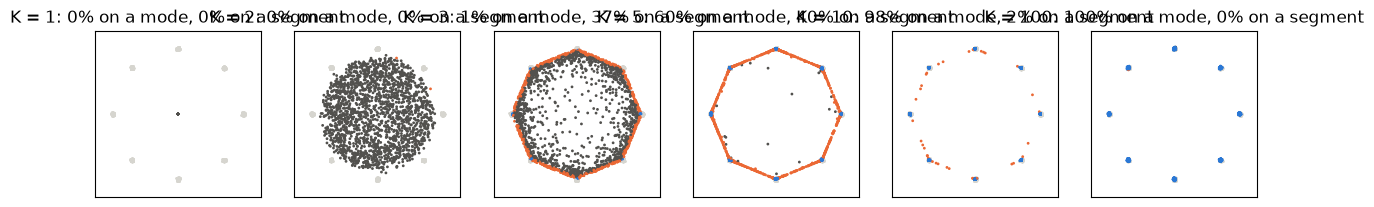

In [2]:
mix = get_mixture("8gaussians")
test, _ = mix.sample(2000, rng)
field = MixtureVelocity(mix, sigma0=1.0)
z = torch.randn(2000, 2)

def placement_colours(x):
    band = 3 * mix.std
    on_mode = np.linalg.norm(x[:, None] - mix.means[None], axis=-1).min(1) < band
    a, b = metrics.neighbour_segments(mix)
    on_seg = ~on_mode & (metrics.distance_to_segments(x, a, b) < band)
    return np.where(on_mode, COLOURS["on mode"], np.where(on_seg, COLOURS["on segment"], COLOURS["elsewhere"]))

def show(ax, x, title):
    ax.scatter(test[:, 0], test[:, 1], s=1, c="#d6d5cf")
    ax.scatter(x[:, 0], x[:, 1], s=1, c=placement_colours(x))
    ax.set_title(title); ax.set_aspect("equal"); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
    ax.set_xticks([]); ax.set_yticks([])

steps = [1, 2, 3, 5, 10, 100]
fig, axes = plt.subplots(1, len(steps), figsize=(15, 2.8))
for ax, k in zip(axes, steps):
    x = samplers.euler(field, z, k).numpy()
    st = metrics.placement_statistics(x, mix)
    show(ax, x, f"K = {k}: {st['on_mode']:.0%} on a mode, {st['on_segment']:.0%} on a segment")
plt.show()

With one step every sample lands on the mean of the data, the centre of the circle, because $x_0$ says nothing about which mode it will reach. With three to five steps the samples that still hesitate between two neighbouring modes land on the segment that joins them (orange). With ten steps or more the posterior is sharp before the last step and almost every sample reaches a mode (blue). The segments therefore come from the integrator and from the coupling, not from training: they appear with the exact field. A trained network adds its own error on top, which the report studies separately.

## 2. Pairing noise and data by optimal transport

The posterior mean lies between the modes because many straight paths pass through the same point and lead to different modes. FM-OT reduces this mixing at its origin. Inside each minibatch of $B$ noise points and $B$ data points it solves the assignment problem

$$\hat\sigma = \arg\min_{\sigma} \sum_{i=1}^{B} \lVert x_0^{(\sigma(i))} - x_1^{(i)} \rVert^2,$$

which is the optimal transport problem between the two empirical measures (Peyré and Cuturi, 2019, Proposition 2.1). `ot_coupling` solves it exactly with the Jonker–Volgenant algorithm of SciPy (Crouse, 2016) and returns the noise reordered so that `x0[i]` is paired with `x1[i]`. We draw the segments of 64 pairs with both couplings.

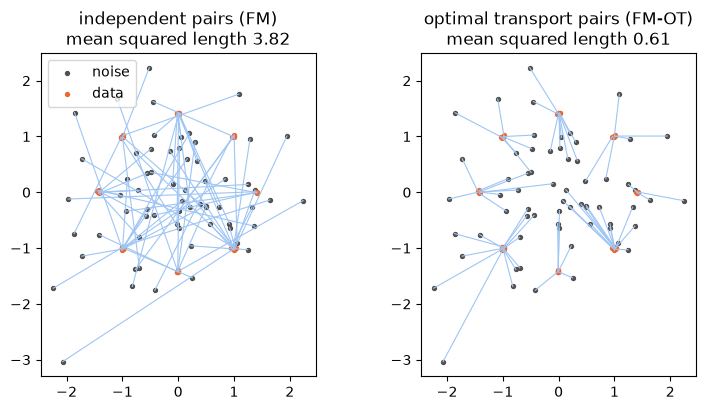

In [3]:
x1 = torch.from_numpy(mix.sample(64, rng)[0])
x0 = torch.randn(64, 2)
x0_ot = ot_coupling(x0, x1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, noise, title in zip(axes, (x0, x0_ot), ("independent pairs (FM)", "optimal transport pairs (FM-OT)")):
    for a, b in zip(noise, x1):
        ax.plot([a[0], b[0]], [a[1], b[1]], c="#9ec5f4", lw=0.8)
    ax.scatter(noise[:, 0], noise[:, 1], s=8, c="#52514e", label="noise")
    ax.scatter(x1[:, 0], x1[:, 1], s=8, c="#eb6834", label="data")
    cost = (noise - x1).pow(2).sum(1).mean().item()
    ax.set_title(f"{title}\nmean squared length {cost:.2f}"); ax.set_aspect("equal")
axes[0].legend(loc="upper left")
plt.show()

The independent segments cross each other in the centre, while the optimal transport segments are shorter and do not cross. With the global optimal plan no two segments would cross, every point would lie on a single segment and the velocity of that segment would be the marginal velocity, so the trajectories would be straight (Tong et al., 2024, Proposition 3.4). A minibatch plan only approximates the global one, and the approximation improves as $B$ grows.

## 3. Training FM and FM-OT

Both models start from the same initialisation, see the same number of iterations and differ only in the pairs. We use the network and the hyperparameters of the report (a perceptron with four hidden layers of 256 units, Adam with rate $10^{-3}$ and minibatches of 256), but 4000 iterations instead of 20 000 so that the notebook runs quickly. We time the assignment separately.

In [4]:
def train(model, coupling, iterations=4000, batch=256, seed=1):
    gen = np.random.default_rng(seed)
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    coupling_time, start = 0.0, time.perf_counter()
    for _ in range(iterations):
        x1 = torch.from_numpy(mix.sample(batch, gen)[0])
        x0 = torch.randn_like(x1)
        if coupling == "ot":
            t0 = time.perf_counter()
            x0 = ot_coupling(x0, x1)
            coupling_time += time.perf_counter() - t0
        loss = flow_matching_loss(model, x1, x0=x0)
        opt.zero_grad(); loss.backward(); opt.step()
    return time.perf_counter() - start, coupling_time

init = MLP2D()
models, times = {}, {}
for name, coupling in (("FM", "independent"), ("FM-OT", "ot")):
    models[name] = MLP2D(); models[name].load_state_dict(init.state_dict())
    times[name] = train(models[name], coupling)
    print(f"{name}: {times[name][0]:.1f} s of training, {times[name][1]:.1f} s of them in the assignment")

FM: 10.8 s of training, 0.0 s of them in the assignment


FM-OT: 28.8 s of training, 18.3 s of them in the assignment


## 4. Samples with few steps

W1 between two real samples of the same size: 0.093


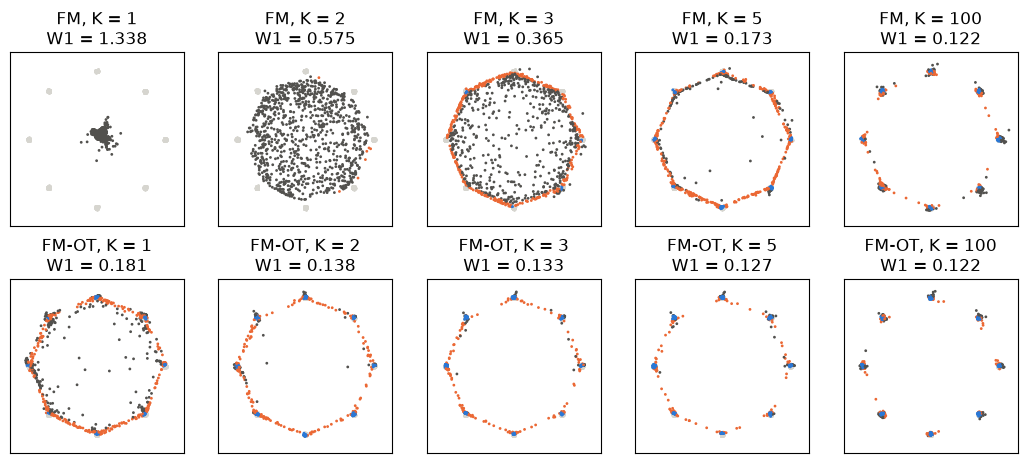

In [5]:
steps = [1, 2, 3, 5, 100]
fig, axes = plt.subplots(2, len(steps), figsize=(13, 5.4))
for row, (name, model) in enumerate(models.items()):
    for ax, k in zip(axes[row], steps):
        x = samplers.euler(model, z[:1000], k).numpy()
        w1 = metrics.w1_exact(x, test[:1000])
        show(ax, x, f"{name}, K = {k}\nW1 = {w1:.3f}")
real_b, _ = mix.sample(1000, np.random.default_rng(1))
print(f"W1 between two real samples of the same size: {metrics.w1_exact(real_b, test[:1000]):.3f}")
plt.show()

FM reproduces the behaviour of the exact field: one step returns the mean of the data and a few steps leave many samples on the segments. FM-OT is already close to the data with one or two steps, since its trajectories barely bend and Euler follows them closely. With 100 steps both models are close to the data, and the remaining difference is the error of learning. $W_1$ is computed exactly as an assignment problem between two samples of the same size, and the $W_1$ between two real samples is the best value a model can reach.

## 5. Straightness and the cost of the assignment

The straightness of Liu et al. (2023, Eq. 3), $S = \int_0^1 \mathbb E \lVert (x(1) - x(0)) - v(x(t), t) \rVert^2 dt$, is zero when every trajectory is a straight segment travelled at constant speed. We approximate it along Euler trajectories of 100 steps and we draw 150 of them.

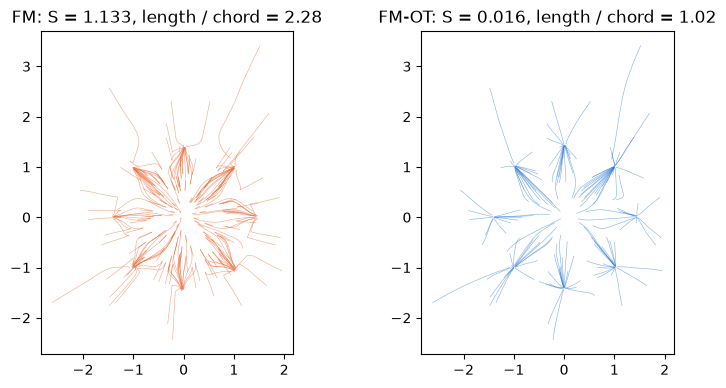

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, (name, model) in zip(axes, models.items()):
    s_value, ratio = samplers.straightness(model, z[:500], 100)
    _, path, _ = samplers.euler(model, z[:150], 100, return_path=True)
    ax.plot(path[:, :, 0], path[:, :, 1], c="#2a78d6" if name == "FM-OT" else "#eb6834", lw=0.4, alpha=0.6)
    ax.set_title(f"{name}: S = {s_value:.3f}, length / chord = {ratio:.2f}"); ax.set_aspect("equal")
plt.show()

The price of these straight trajectories is the assignment. The algorithm of Jonker and Volgenant costs $O(B^3)$ in the worst case, so the cost per point grows with the minibatch while the coupling approaches the global plan. We time one assignment for several minibatch sizes (median of five).

In [7]:
ot_coupling(torch.randn(16, 2), torch.randn(16, 2))  # the first call loads SciPy and is slower
for b in (16, 64, 256, 1024):
    runs = []
    for _ in range(5):
        xa, xb = torch.randn(b, 2), torch.from_numpy(mix.sample(b, rng)[0])
        t0 = time.perf_counter()
        ot_coupling(xa, xb)
        runs.append(time.perf_counter() - t0)
    ms = 1000 * float(np.median(runs))
    print(f"B = {b:4d}: {ms:8.2f} ms per assignment, {1000 * ms / b:7.2f} microseconds per point")

B =   16:     0.04 ms per assignment,    2.57 microseconds per point
B =   64:     0.27 ms per assignment,    4.27 microseconds per point
B =  256:     4.49 ms per assignment,   17.55 microseconds per point


B = 1024:   131.31 ms per assignment,  128.23 microseconds per point


## 6. Results of the full study

The full study trains every method for 20 000 iterations on three mixtures, adds RF-2 and DDPM as standards of comparison, sweeps the width of the noise and the minibatch size, and repeats the comparison on the digits 3 and 4 of MNIST. If the result files exist, we show the $W_1$ of the main comparison on the eight Gaussians and the verdicts of the hypotheses.

In [8]:
import json
import pandas as pd

path = ROOT / "results" / "2d_metrics.csv"
if path.exists():
    m = pd.read_csv(path)
    m = m[(m.experiment == "main") & (m.dataset == "8gaussians")]
    m = m.drop_duplicates(["method", "sampler", "steps"], keep="last")  # a repeated evaluation replaces the old one
    m["method"] = m.method + " / " + m.sampler
    display(m.pivot_table(index="method", columns="steps", values="w1").round(3))
hyp = ROOT / "results" / "hypotheses.json"
if hyp.exists():
    print(json.dumps(json.loads(hyp.read_text()), indent=2))

steps,1,2,3,4,5,10,100,1000
method,,,,,,,,
ddpm / ddim,11.016,1.015,0.954,0.776,0.582,0.296,0.221,0.218
ddpm / ddpm,11.016,1.200,0.788,0.613,0.481,0.254,0.162,0.158
fm / euler,1.336,0.602,0.347,0.228,0.172,0.122,0.109,0.110
fmot / euler,0.179,0.097,0.089,0.089,0.086,0.086,0.087,0.087
rf2 / euler,0.133,0.128,0.129,0.130,0.126,0.126,0.125,0.125


{
  "H1": "partly supported",
  "H2": "supported",
  "H3": "supported",
  "H4": "supported",
  "H5": "partly supported",
  "H6": "supported"
}


## Summary

Few steps of Euler leave the samples of flow matching on the posterior mean of the data, which lies on the segments between neighbouring modes while the trajectory has not chosen a mode yet. This happens with the exact field, so it does not come from training. FM-OT pairs noise and data by optimal transport inside each minibatch, so that the paths cross less, the trajectories become almost straight and one or two steps already give useful samples. Its cost is the assignment, which grows quickly with the minibatch. The report quantifies these effects and compares FM-OT with reflow and with a diffusion model from 1 to 1000 steps.